# Homework 7.1 - Part II

## Numerical Simulation of the Conditioned Lorenz System

This notebook constructs the numerical map

$$
c
\longmapsto
\Gamma_c.
$$

The reference condition is

$$
c_\star
=
\left(
10,
28,
\frac{8}{3},
1,
1,
1,
25
\right).
$$

The Lorenz equations are

$$
\dot{x}
=
\sigma(y-x),
$$

$$
\dot{y}
=
x(\rho-z)-y,
$$

$$
\dot{z}
=
xy-\beta z.
$$

The assignment asks for:

1. the three time series;
2. the three-dimensional phase portrait;
3. a two-dimensional phase-space projection;
4. a numerical check that the computed solution satisfies the Lorenz equations.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw7_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw7_1"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

config_path = DATA_DIR / "part1_pipeline_configuration.json"

if not config_path.exists():
    raise FileNotFoundError(
        "Run Part I first so the pipeline configuration is frozen."
    )

config = json.loads(
    config_path.read_text(
        encoding="utf-8"
    )
)

c = config["reference_condition"]

SIGMA = float(c["sigma"])
RHO = float(c["rho"])
BETA = float(c["beta"])
X0 = float(c["x0"])
Y0 = float(c["y0"])
Z0 = float(c["z0"])
T = float(c["T"])

DT = float(
    config[
        "time_discretization"
    ]["dt"]
)

print("Reference condition:", c)
print("Sampling interval dt =", DT)

Reference condition: {'sigma': 10.0, 'rho': 28.0, 'beta': 2.6666666666666665, 'x0': 1.0, 'y0': 1.0, 'z0': 1.0, 'T': 25.0}
Sampling interval dt = 0.01


# 1. Define the Lorenz vector field

In [2]:
def lorenz_rhs(t, state, sigma, rho, beta):
    x, y, z = state

    return np.array([
        sigma * (y - x),
        x * (rho - z) - y,
        x * y - beta * z,
    ], dtype=float)

# 2. Integrate the system

The ODE is solved with `DOP853`, using tight internal tolerances.

The solver evaluates the high-accuracy adaptive solution on the fixed grid

$$
t_j=j\Delta t,
\qquad
\Delta t=0.01.
$$

In [3]:
time = np.arange(
    0.0,
    T + 0.5 * DT,
    DT,
)

initial_state = np.array(
    [X0, Y0, Z0],
    dtype=float,
)

solution = solve_ivp(
    fun=lambda t, state: lorenz_rhs(
        t,
        state,
        SIGMA,
        RHO,
        BETA,
    ),
    t_span=(0.0, T),
    y0=initial_state,
    t_eval=time,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)

if not solution.success:
    raise RuntimeError(
        solution.message
    )

states = solution.y.T

trajectory = pd.DataFrame({
    "time": solution.t,
    "x": states[:, 0],
    "y": states[:, 1],
    "z": states[:, 2],
})

trajectory_path = (
    DATA_DIR
    / "part2_reference_trajectory.csv"
)

trajectory.to_csv(
    trajectory_path,
    index=False,
)

condition_path = (
    DATA_DIR
    / "part2_reference_condition.json"
)

condition_path.write_text(
    json.dumps(
        c,
        indent=2,
    ),
    encoding="utf-8",
)

print("Solver success:", solution.success)
print("Stored samples:", len(trajectory))
print("Trajectory shape:", states.shape)
print("Saved:", trajectory_path.resolve())

Solver success: True
Stored samples: 2501
Trajectory shape: (2501, 3)
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\data\hw7_1\part2_reference_trajectory.csv


# 3. Plot the three time series

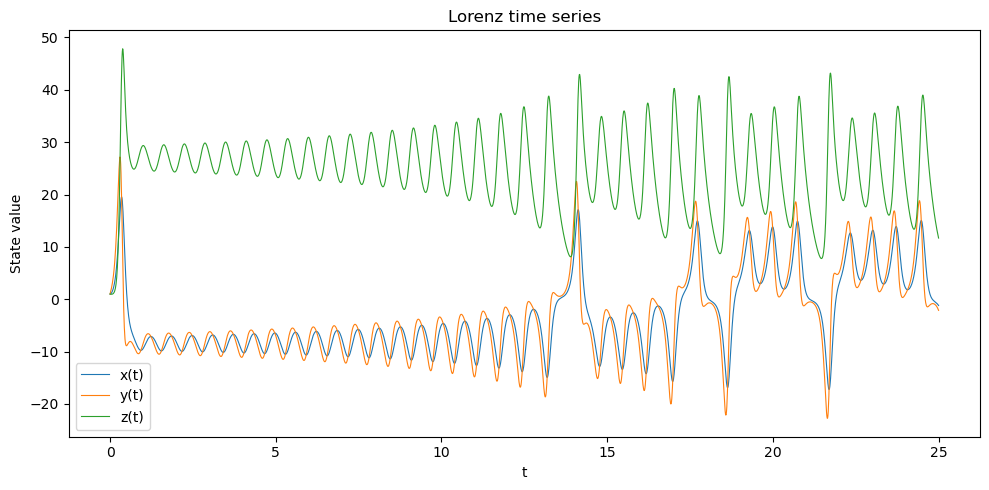

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\result images\hw7_1\part2_lorenz_time_series.png


In [4]:
plt.figure(figsize=(10, 5))

plt.plot(
    trajectory["time"],
    trajectory["x"],
    label="x(t)",
    linewidth=0.8,
)

plt.plot(
    trajectory["time"],
    trajectory["y"],
    label="y(t)",
    linewidth=0.8,
)

plt.plot(
    trajectory["time"],
    trajectory["z"],
    label="z(t)",
    linewidth=0.8,
)

plt.xlabel("t")
plt.ylabel("State value")
plt.title("Lorenz time series")
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "part2_lorenz_time_series.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# 4. Three-dimensional phase portrait

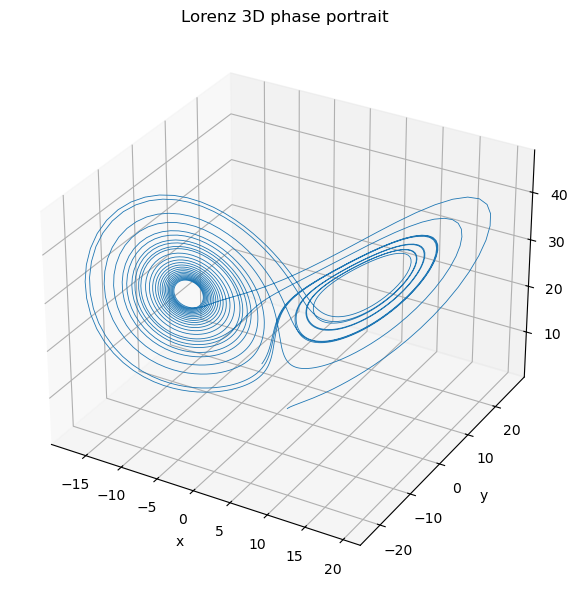

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\result images\hw7_1\part2_lorenz_phase_portrait_3d.png


In [5]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(
    111,
    projection="3d",
)

ax.plot(
    trajectory["x"],
    trajectory["y"],
    trajectory["z"],
    linewidth=0.6,
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title(
    "Lorenz 3D phase portrait"
)

plt.tight_layout()

path = (
    RESULT_DIR
    / "part2_lorenz_phase_portrait_3d.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# 5. Two-dimensional projection

We use the

$$
(x,z)
$$

projection because it preserves the visually distinct two-lobe structure while producing a simple two-dimensional representation.

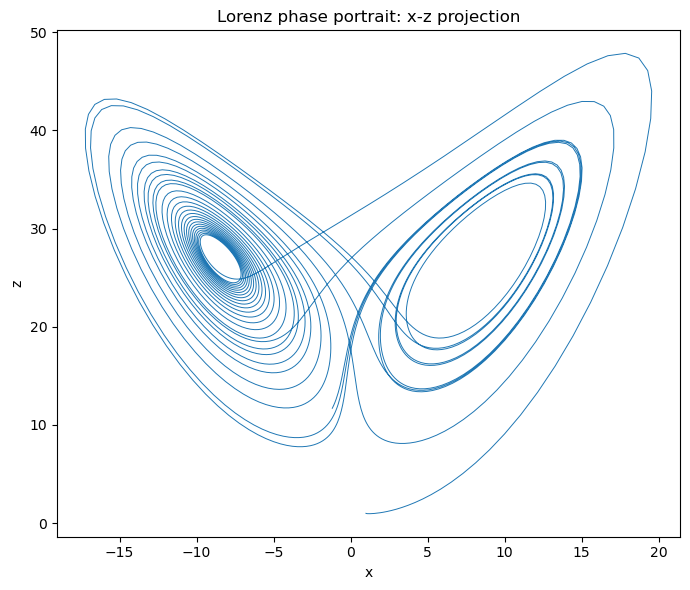

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\result images\hw7_1\part2_lorenz_xz_projection.png


In [6]:
plt.figure(figsize=(7, 6))

plt.plot(
    trajectory["x"],
    trajectory["z"],
    linewidth=0.7,
)

plt.xlabel("x")
plt.ylabel("z")
plt.title(
    "Lorenz phase portrait: x-z projection"
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "part2_lorenz_xz_projection.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# 6. Numerical verification of the Lorenz equations

The computed trajectory satisfies the ODE if

$$
\frac{d}{dt}
\gamma_c(t)
\approx
F(\gamma_c(t)).
$$

We estimate the derivative from the stored trajectory using second-order finite differences:

$$
\dot{\Gamma}_{\mathrm{FD}}(t_i)
\approx
\frac{
\Gamma(t_{i+1})
-
\Gamma(t_{i-1})
}{
2\Delta t
}.
$$

Then compare this estimate with the exact Lorenz right-hand side evaluated at the computed state.

This test contains both ODE-solver error and finite-difference derivative error.

The first and last samples are excluded from the reported summary because the centered finite-difference formula requires one sample on each side.

In [7]:
numerical_derivatives = np.column_stack([
    np.gradient(
        trajectory[column].to_numpy(),
        trajectory["time"].to_numpy(),
        edge_order=2,
    )
    for column in [
        "x",
        "y",
        "z",
    ]
])

rhs_values = np.vstack([
    lorenz_rhs(
        t,
        state,
        SIGMA,
        RHO,
        BETA,
    )
    for t, state in zip(
        trajectory["time"].to_numpy(),
        states,
    )
])

residual = (
    numerical_derivatives
    - rhs_values
)

interior = slice(
    1,
    -1,
)

component_names = [
    "x",
    "y",
    "z",
]

verification_rows = []

for j, name in enumerate(
    component_names
):
    component_residual = (
        residual[
            interior,
            j,
        ]
    )

    rhs_component = (
        rhs_values[
            interior,
            j,
        ]
    )

    rmse = float(
        np.sqrt(
            np.mean(
                component_residual**2
            )
        )
    )

    rhs_rms = float(
        np.sqrt(
            np.mean(
                rhs_component**2
            )
        )
    )

    relative_rmse = (
        rmse / rhs_rms
        if rhs_rms > 0
        else np.nan
    )

    verification_rows.append({
        "component": name,
        "rmse_derivative_residual": rmse,
        "rhs_rms": rhs_rms,
        "relative_rmse": relative_rmse,
        "max_absolute_residual": float(
            np.max(
                np.abs(
                    component_residual
                )
            )
        ),
        "median_absolute_residual": float(
            np.median(
                np.abs(
                    component_residual
                )
            )
        ),
    })


verification = pd.DataFrame(
    verification_rows
)

verification_path = (
    DATA_DIR
    / "part2_ode_verification.csv"
)

verification.to_csv(
    verification_path,
    index=False,
)

print(
    verification.to_string(
        index=False
    )
)
print()
print("Saved:", verification_path.resolve())

component  rmse_derivative_residual   rhs_rms  relative_rmse  max_absolute_residual  median_absolute_residual
        x                  0.121915 35.980007       0.003388               1.009057                  0.027285
        y                  0.315924 55.534392       0.005689               3.817776                  0.041525
        z                  0.317614 66.525989       0.004774               3.496838                  0.046002

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\data\hw7_1\part2_ode_verification.csv


## Residual norm over time

Define

$$
r_i
=
\left\|
\dot{\Gamma}_{\mathrm{FD}}(t_i)
-
F(\Gamma(t_i))
\right\|_2.
$$

The plot below checks whether the derivative mismatch remains small relative to the characteristic derivative scale.

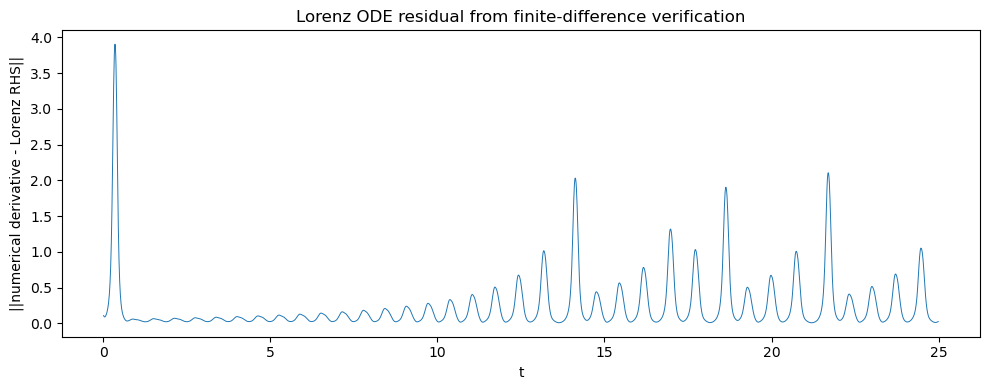

Relative vector RMSE: 0.004947949082590294
Saved summary: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\data\hw7_1\part2_ode_verification_summary.json
Saved figure: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\result images\hw7_1\part2_ode_residual_norm.png


In [8]:
residual_norm = np.linalg.norm(
    residual,
    axis=1,
)

rhs_norm = np.linalg.norm(
    rhs_values,
    axis=1,
)

relative_vector_rmse = (
    np.sqrt(
        np.mean(
            residual_norm[
                interior
            ]**2
        )
    )
    /
    np.sqrt(
        np.mean(
            rhs_norm[
                interior
            ]**2
        )
    )
)

summary = {
    "relative_vector_rmse": float(
        relative_vector_rmse
    ),
    "mean_residual_norm": float(
        residual_norm[
            interior
        ].mean()
    ),
    "median_residual_norm": float(
        np.median(
            residual_norm[
                interior
            ]
        )
    ),
    "p95_residual_norm": float(
        np.quantile(
            residual_norm[
                interior
            ],
            0.95,
        )
    ),
}

summary_path = (
    DATA_DIR
    / "part2_ode_verification_summary.json"
)

summary_path.write_text(
    json.dumps(
        summary,
        indent=2,
    ),
    encoding="utf-8",
)

plt.figure(figsize=(10, 4))

plt.plot(
    trajectory["time"].to_numpy()[
        1:-1
    ],
    residual_norm[
        1:-1
    ],
    linewidth=0.7,
)

plt.xlabel("t")
plt.ylabel(
    "||numerical derivative - Lorenz RHS||"
)
plt.title(
    "Lorenz ODE residual from finite-difference verification"
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "part2_ode_residual_norm.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Relative vector RMSE:", relative_vector_rmse)
print("Saved summary:", summary_path.resolve())
print("Saved figure:", path.resolve())

# 7. Interpretation of the verification

A small derivative residual supports the claim that the stored numerical trajectory is consistent with the Lorenz differential equations at the chosen sampling resolution.

This is stronger than simply observing a butterfly-shaped plot.

The trajectory is accepted as a numerical representation of the Lorenz solution because:

1. it was produced by a high-accuracy ODE integrator;
2. centered finite-difference derivatives can be estimated from the stored samples at the chosen sampling scale;
3. those derivative estimates agree with the Lorenz vector field to small relative error.

The exact numerical residual values produced above should be cited in the final reflection after this notebook has been executed.

# Part II Conclusion

The first scientific map has now been implemented:

$$
\boxed{
c_\star
\longmapsto
\Gamma_{c_\star}.
}
$$

The notebook saves the numerical trajectory, three required visualizations, and quantitative ODE-residual diagnostics.

Part III will define the second map

$$
\Gamma_c
\longmapsto
I_c
$$

and analyze what information is lost when the mathematical trajectory is converted into a raster image.